# 06. Bốn phương án neo với năm hạt giống

Sổ tay notebook 04 chạy ba hạt giống, trong khi lần chạy chốt dùng năm. Bảng bốn phương án neo là kết quả tiêu đề của đề tài, nên nó cần theo chuẩn cao nhất trong toàn bộ báo cáo.

Sổ tay này chỉ chạy hai hạt giống còn thiếu là 3 và 4, rồi gộp với ba hạt giống đã có trong `bo_sung_04_neo_abcd`. Cách làm này tránh chạy lại những gì đã có, và vẫn cho ra một bảng năm hạt giống đầy đủ.

Điều kiện hợp lệ của phép gộp: cùng dữ liệu đã tiền xử lý, cùng kiến trúc, cùng ngân sách huấn luyện, cùng hàm mất mát, chỉ khác hạt giống khởi tạo. Sổ tay tự kiểm tra các điều kiện này trước khi gộp, và dừng nếu phát hiện lệch.

> **Vị trí trong chuỗi tái lập:** notebook 06 trên tổng số 31. Thứ tự chạy và sơ đồ phụ thuộc nằm trong `README.md`.
>
> **Cần chạy trước:** 03-Tien_xu_ly_va_thuc_nghiem_chinh, 04-Bon_phuong_an_neo.
>
> **Thư mục kết quả:** `Output/processed/bo_sung_13_neo_abcd_nam_hat_giong/`.
>
> **Mã định danh nội bộ:** `W2_13`. Mã này còn xuất hiện trong tên khóa JSON, tên hình và nhật ký chạy; nó được giữ nguyên để không phá phép đối chiếu chéo và mã băm của bản khai báo trước.

## 1. Tham số và đường dẫn

In [1]:
#@title Tham số chạy { display-mode: "form" }
PROJECT_DIR = "/content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4"  #@param {type:"string"}
READ_TAG = "chot"  #@param {type:"string"}
RUN_TAG = "bo_sung_13_neo_abcd_nam_hat_giong"  #@param {type:"string"}
DANH_SACH_NEO = "A,B,C,D"  #@param {type:"string"}
DANH_SACH_HAT_GIONG_MOI = "3,4"  #@param {type:"string"}
NGUON_ABCD = "bo_sung_04_neo_abcd"  #@param {type:"string"}
SEQ_LEN = 36     #@param {type:"integer"}
PRED_LEN = 12    #@param {type:"integer"}
N_SEEDS = 3      #@param {type:"integer"}
EPOCHS = 60      #@param {type:"integer"}
PATIENCE = 10    #@param {type:"integer"}
BATCH = 128      #@param {type:"integer"}
LR = 1e-3        #@param {type:"number"}

NEO = [t.strip() for t in DANH_SACH_NEO.split(",") if t.strip()]
HAT_GIONG_MOI = [int(t) for t in DANH_SACH_HAT_GIONG_MOI.split(",") if t.strip()]
import os, sys, json, time, random, datetime, platform, importlib, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
else:
    PROJECT_DIR = os.environ.get("P12_PROJECT", "./AIO2026_Conquer_M4_DLinear_NLinear_Slot4")

PROJECT = Path(PROJECT_DIR)
OUT = PROJECT / "Output"
# Đọc dữ liệu đã tiền xử lý của lần chạy chốt, ghi kết quả sang một thư mục con riêng.
PROC = OUT / "processed" / READ_TAG
RUN_DIR = OUT / "processed" / RUN_TAG
RUNS = RUN_DIR / "runs"
FIGS = RUN_DIR / "figures"
LOGS = RUN_DIR / "logs"
for d in (RUN_DIR, RUNS, FIGS, LOGS):
    d.mkdir(parents=True, exist_ok=True)

assert (PROC / "meta.json").exists(), (
    "Không thấy dữ liệu đã tiền xử lý trong " + str(PROC) +
    ". Hãy chạy notebook 03-Tien_xu_ly_va_thuc_nghiem_chinh trước.")
meta = json.loads((PROC / "meta.json").read_text())
channels = meta["channels"]
EPS = 1e-8

print("Thư mục đọc :", PROC)
print("Thư mục ghi :", RUN_DIR)
print("Số kênh     :", len(channels), "| ngưỡng cắt sigma của lần chạy nguồn:", meta["clip_sigma"])


Mounted at /content/drive
Thư mục đọc : /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/chot
Thư mục ghi : /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/bo_sung_13_neo_abcd_nam_hat_giong
Số kênh     : 37 | ngưỡng cắt sigma của lần chạy nguồn: 0.0


In [2]:
REQUIRED = {"numpy": "1.24.0", "torch": "2.0.0", "matplotlib": "3.7.0", "scipy": "1.10.0"}


def ver_tuple(v):
    out = []
    for part in str(v).split(".")[:3]:
        digits = "".join(ch for ch in part if ch.isdigit())
        out.append(int(digits) if digits else 0)
    return tuple(out + [0] * (3 - len(out)))


missing = []
for name, floor in REQUIRED.items():
    try:
        mod = importlib.import_module(name)
        if ver_tuple(mod.__version__) < ver_tuple(floor):
            missing.append(name + ">=" + floor)
    except ImportError:
        missing.append(name + ">=" + floor)

if missing:
    print("Cài bổ sung:", " ".join(missing))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q"] + missing, check=True)

import numpy as np
import torch
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats

ENV = {
    "timestamp": datetime.datetime.now().isoformat(timespec="seconds"),
    "run_tag": RUN_TAG,
    "read_tag": READ_TAG,
    "python": platform.python_version(),
    "numpy": np.__version__,
    "torch": torch.__version__,
    "matplotlib": matplotlib.__version__,
    "scipy": scipy.__version__,
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
}
stamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
(LOGS / ("env_" + stamp + ".json")).write_text(json.dumps(ENV, ensure_ascii=False, indent=2))
for k, v in ENV.items():
    print(k.ljust(12), v)


timestamp    2026-10-14T18:14:14
run_tag      bo_sung_13_neo_abcd_nam_hat_giong
read_tag     chot
python       3.13.15
numpy        2.1.3
torch        2.11.0+cu130
matplotlib   3.10.0
scipy        1.16.3
gpu          Tesla T4


In [3]:
PALETTE = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9", "#000000"]

matplotlib.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
    "legend.frameon": False,
    "lines.linewidth": 1.4,
    "axes.prop_cycle": matplotlib.cycler(color=PALETTE),
    "figure.constrained_layout.use": True,
})


def luu_hinh(fig, ten):
    duong = FIGS / ten
    fig.savefig(duong)
    print("Đã lưu", duong)
    return duong


print("Đã đặt quy ước trình bày hình")


Đã đặt quy ước trình bày hình


## 2. Mô hình, chỉ số và hàm huấn luyện

In [4]:
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"


def moving_avg(x, kernel_size=25):
    front = x[:, :1, :].repeat(1, (kernel_size - 1) // 2, 1)
    end = x[:, -1:, :].repeat(1, kernel_size - (kernel_size - 1) // 2 - 1, 1)
    xp = torch.cat([front, x, end], dim=1).permute(0, 2, 1)
    return F.avg_pool1d(xp, kernel_size=kernel_size, stride=1).permute(0, 2, 1)


def last_observed(x, mask):
    # Trả về giá trị quan sát thật gần nhất và số giờ đã trôi qua kể từ phép đo đó.
    B, Lx, C = x.shape
    pos = torch.arange(Lx, device=x.device).view(1, Lx, 1).expand(B, Lx, C)
    idx = torch.where(mask > 0, pos, torch.full_like(pos, -1))
    t_star = idx.max(dim=1).values
    has = t_star >= 0
    val = torch.gather(x, 1, t_star.clamp(min=0).unsqueeze(1)).squeeze(1)
    val = torch.where(has, val, torch.zeros_like(val))
    dt = torch.where(has, (Lx - 1 - t_star).float(), torch.full_like(val, float(Lx)))
    return val, dt


def first_observed(x, mask):
    # Trả về giá trị quan sát thật xa nhất trong cửa sổ, dùng cho phép thử đối chứng.
    B, Lx, C = x.shape
    pos = torch.arange(Lx, device=x.device).view(1, Lx, 1).expand(B, Lx, C)
    idx = torch.where(mask > 0, pos, torch.full_like(pos, Lx))
    t_star = idx.min(dim=1).values
    has = t_star < Lx
    val = torch.gather(x, 1, t_star.clamp(max=Lx - 1).unsqueeze(1)).squeeze(1)
    val = torch.where(has, val, torch.zeros_like(val))
    dt = torch.where(has, (Lx - 1 - t_star).float(), torch.full_like(val, float(Lx)))
    return val, dt


# Tám định nghĩa neo. Z, A, B, O là neo tĩnh; C, D, E, F có cổng suy giảm học được.
# E và F giống C và D về công thức, chỉ khác điểm khởi tạo của tham số suy giảm.
NEO_HOP_LE = ("Z", "A", "B", "O", "C", "D", "E", "F")
KHOI_TAO_CONG = {"C": 0.0, "D": 0.0, "E": -6.0, "F": -6.0}


class LinearFamily(nn.Module):
    # Một lớp bao trùm cả DLinear và NLinear. Neo áp dụng cho cả hai họ, nên phép so sánh
    # Giữa hai họ và giữa các neo không bị lệch bởi nhánh mã khác nhau.
    def __init__(self, seq_len, pred_len, n_channels, kind="nlinear", anchor="A",
                 use_mask_channel=True, kernel_size=25):
        super().__init__()
        assert kind in ("dlinear", "nlinear")
        assert anchor in NEO_HOP_LE, "Neo không hợp lệ: " + str(anchor)
        self.L, self.H, self.C = seq_len, pred_len, n_channels
        self.kind, self.anchor = kind, anchor
        self.use_mask_channel = use_mask_channel
        self.kernel_size = kernel_size
        in_dim = seq_len * (2 if use_mask_channel else 1)
        if kind == "dlinear":
            self.lin_seasonal = nn.Linear(in_dim, pred_len)
            self.lin_trend = nn.Linear(in_dim, pred_len)
        else:
            self.lin = nn.Linear(in_dim, pred_len)
        if anchor in ("C", "E"):
            self.w_decay = nn.Parameter(torch.full((1,), KHOI_TAO_CONG[anchor]))
        elif anchor in ("D", "F"):
            self.w_decay = nn.Parameter(torch.full((n_channels,), KHOI_TAO_CONG[anchor]))

    def compute_anchor(self, x, mask):
        if self.anchor == "Z":
            return torch.zeros_like(x[:, -1, :])
        if self.anchor == "A":
            return x[:, -1, :]
        if self.anchor == "O":
            val_o, _ = first_observed(x, mask)
            return val_o
        val, dt = last_observed(x, mask)
        if self.anchor == "B":
            return val
        rate = F.softplus(self.w_decay)
        return torch.exp(-rate.view(1, -1) * dt) * val

    def _flatten(self, x, mask):
        B, Lx, C = x.shape
        xt = x.permute(0, 2, 1).reshape(B * C, Lx)
        if not self.use_mask_channel:
            return xt
        mt = mask.permute(0, 2, 1).reshape(B * C, Lx).float()
        return torch.cat([xt, mt], dim=-1)

    def forward(self, x, mask):
        B, Lx, C = x.shape
        a = self.compute_anchor(x, mask)
        xr = x - a.unsqueeze(1)
        if self.kind == "nlinear":
            z = self.lin(self._flatten(xr, mask))
        else:
            trend = moving_avg(xr, self.kernel_size)
            z = self.lin_seasonal(self._flatten(xr - trend, mask)) + \
                self.lin_trend(self._flatten(trend, mask))
        return z.view(B, C, self.H).permute(0, 2, 1) + a.unsqueeze(1)


class Persistence(nn.Module):
    # Đường cơ sở không tham số: giữ nguyên phép đo thật gần nhất cho mọi bước tương lai.
    def __init__(self, pred_len):
        super().__init__()
        self.H = pred_len

    def forward(self, x, mask):
        val, _ = last_observed(x, mask)
        return val.unsqueeze(1).repeat(1, self.H, 1)


def dat_hat_giong(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def tong_theo_ho_so(y_hat, y, m):
    m = m.astype(np.float64)
    se = (m * (y_hat - y) ** 2).reshape(len(m), -1).sum(axis=1)
    ae = (m * np.abs(y_hat - y)).reshape(len(m), -1).sum(axis=1)
    dem = m.reshape(len(m), -1).sum(axis=1)
    return se, ae, dem


def khoang_tin_cay(se, ae, dem, n_boot=2000, seed=0, alpha=0.05):
    # Lấy mẫu lại ở cấp bệnh nhân, không phải cấp điểm đo, vì các điểm trong cùng
    # Một hồ sơ không độc lập với nhau.
    rng = np.random.default_rng(seed)
    N = len(dem)
    mses, maes = np.empty(n_boot), np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, N, N)
        mau = dem[idx].sum() + EPS
        mses[b] = se[idx].sum() / mau
        maes[b] = ae[idx].sum() / mau
    lo, hi = 100 * alpha / 2, 100 * (1 - alpha / 2)
    return {
        "mse": float(se.sum() / (dem.sum() + EPS)),
        "mse_ci": [float(np.percentile(mses, lo)), float(np.percentile(mses, hi))],
        "mae": float(ae.sum() / (dem.sum() + EPS)),
        "mae_ci": [float(np.percentile(maes, lo)), float(np.percentile(maes, hi))],
        "mae_theo_ho_so": float(np.mean(ae / np.maximum(dem, 1.0))),
    }


print("Thiết bị tính toán:", DEVICE)


Thiết bị tính toán: cuda


In [5]:
def nap_lat(ten, L, H):
    d = np.load(PROC / (ten + ".npz"))
    Xd, Md = d["X"], d["M"]
    assert Xd.shape[1] >= L + H, "Lưới thời gian ngắn hơn L cộng H"
    x, mxx = Xd[:, :L], Md[:, :L]
    y, myy = Xd[:, L:L + H], Md[:, L:L + H]
    giu = myy.reshape(len(myy), -1).sum(axis=1) > 0
    return (torch.from_numpy(x[giu]).float(), torch.from_numpy(mxx[giu]).float(),
            torch.from_numpy(y[giu]).float(), torch.from_numpy(myy[giu]).float(),
            int(giu.sum()), int((~giu).sum()))


SPLITS = {}
for ten in ("train", "val", "test"):
    x, mxx, y, myy, giu, bo = nap_lat(ten, SEQ_LEN, PRED_LEN)
    SPLITS[ten] = TensorDataset(x, mxx, y, myy)
    print(ten.ljust(6), "giữ", giu, "hồ sơ, bỏ", bo, "hồ sơ không có mục tiêu quan sát thật")

N_CH = SPLITS["train"].tensors[0].shape[-1]
print("Số kênh:", N_CH)


train  giữ 5559 hồ sơ, bỏ 41 hồ sơ không có mục tiêu quan sát thật
val    giữ 794 hồ sơ, bỏ 6 hồ sơ không có mục tiêu quan sát thật
test   giữ 1585 hồ sơ, bỏ 15 hồ sơ không có mục tiêu quan sát thật
Số kênh: 37


In [6]:
def tinh_mat_mat(pred, y, m, loai, delta=1.0):
    # Mọi hàm mất mát chỉ tính trên các ô có phép đo thật, mẫu số là tổng mặt nạ.
    if loai == "mse":
        thanh_phan = (pred - y) ** 2
    elif loai == "mae":
        thanh_phan = (pred - y).abs()
    elif loai == "huber":
        thanh_phan = F.huber_loss(pred, y, reduction="none", delta=delta)
    else:
        raise ValueError("Không biết loại mất mát " + str(loai))
    return (m * thanh_phan).sum() / (m.sum() + EPS)


def chay_mot_cau_hinh(kind, anchor="A", seed=0, nhan=None, loai_mat_mat="mse",
                      huber_delta=1.0, epochs=None, patience=None, ghi_file=True,
                      lat=None, thu_muc=None):
    """Huấn luyện một cấu hình, đánh giá trên tập kiểm tra, ghi kết quả ra thư mục runs."""
    epochs = EPOCHS if epochs is None else epochs
    patience = PATIENCE if patience is None else patience
    lat = SPLITS if lat is None else lat
    thu_muc = RUNS if thu_muc is None else thu_muc
    dat_hat_giong(seed)

    if kind == "persistence":
        model = Persistence(PRED_LEN).to(DEVICE)
        so_tham_so = 0
    else:
        model = LinearFamily(SEQ_LEN, PRED_LEN, N_CH, kind=kind, anchor=anchor).to(DEVICE)
        so_tham_so = sum(p.numel() for p in model.parameters() if p.requires_grad)

    loaders = {k: DataLoader(v, batch_size=BATCH, shuffle=(k == "train"))
               for k, v in lat.items()}

    t0 = time.time()
    tot_nhat, trang_thai, xau, lich_su = float("inf"), None, 0, []
    val_mse_luc_tot_nhat = None
    if kind != "persistence":
        opt = torch.optim.Adam(model.parameters(), lr=LR)
        for ep in range(epochs):
            model.train()
            for x, mxx, y, myy in loaders["train"]:
                x, mxx, y, myy = [t.to(DEVICE) for t in (x, mxx, y, myy)]
                opt.zero_grad()
                mat_mat = tinh_mat_mat(model(x, mxx), y, myy, loai_mat_mat, huber_delta)
                mat_mat.backward()
                opt.step()
            model.eval()
            with torch.no_grad():
                tu = tu_mse = mau = 0.0
                for x, mxx, y, myy in loaders["val"]:
                    x, mxx, y, myy = [t.to(DEVICE) for t in (x, mxx, y, myy)]
                    p = model(x, mxx)
                    if loai_mat_mat == "mse":
                        tp = (p - y) ** 2
                    elif loai_mat_mat == "mae":
                        tp = (p - y).abs()
                    else:
                        tp = F.huber_loss(p, y, reduction="none", delta=huber_delta)
                    tu += float((myy * tp).sum())
                    tu_mse += float((myy * (p - y) ** 2).sum())
                    mau += float(myy.sum())
                val_loss = tu / (mau + EPS)
                val_mse = tu_mse / (mau + EPS)
            lich_su.append(val_loss)
            # Dừng sớm theo đúng hàm mất mát đang huấn luyện, để phép so sánh không thiên lệch.
            if val_loss < tot_nhat - 1e-6:
                tot_nhat, xau, val_mse_luc_tot_nhat = val_loss, 0, val_mse
                trang_thai = {k: v.detach().clone() for k, v in model.state_dict().items()}
            else:
                xau += 1
                if xau >= patience:
                    break
        if trang_thai is not None:
            model.load_state_dict(trang_thai)
    thoi_gian = time.time() - t0

    model.eval()
    du_bao = []
    with torch.no_grad():
        for x, mxx, y, myy in loaders["test"]:
            du_bao.append(model(x.to(DEVICE), mxx.to(DEVICE)).cpu().numpy())
    yhat = np.concatenate(du_bao)
    y_te = lat["test"].tensors[2].numpy()
    my_te = lat["test"].tensors[3].numpy()
    se, ae, dem = tong_theo_ho_so(yhat, y_te, my_te)
    ket = khoang_tin_cay(se, ae, dem, seed=seed)

    ten = nhan or (kind + "_neo" + anchor + "_" + loai_mat_mat + "_s" + str(seed))
    payload = {"name": ten, "kind": kind, "anchor": anchor, "seed": seed,
               "loai_mat_mat": loai_mat_mat, "huber_delta": huber_delta,
               "seq_len": SEQ_LEN, "pred_len": PRED_LEN, "n_params": so_tham_so,
               "protocol": meta["protocol"], "read_tag": READ_TAG, "run_tag": RUN_TAG,
               "val_loss": tot_nhat if tot_nhat < float("inf") else None,
               "val_mse_obs": val_mse_luc_tot_nhat,
               "train_time_sec": round(thoi_gian, 2), "device": DEVICE,
               "history": lich_su, "test": ket, "env": ENV}
    if ghi_file:
        thu_muc.mkdir(parents=True, exist_ok=True)
        (thu_muc / (ten + ".json")).write_text(json.dumps(payload, ensure_ascii=False, indent=2))
        np.savez_compressed(thu_muc / (ten + "_patient_sums.npz"), se=se, ae=ae, n=dem)
    print(ten.ljust(32), "MSE_obs", round(ket["mse"], 4), "| MAE_obs", round(ket["mae"], 4),
          "|", int(thoi_gian), "giây |", so_tham_so, "tham số")
    return payload


print("Đã định nghĩa hàm huấn luyện")


Đã định nghĩa hàm huấn luyện


In [7]:
def hieu_so_bat_cap(se_a, ae_a, se_b, ae_b, dem, n_boot=2000, seed=0, alpha=0.05):
    """Khoảng tin cậy cho hiệu số hai mô hình, lấy mẫu lại cùng một danh sách bệnh nhân."""
    rng = np.random.default_rng(seed)
    N = len(dem)
    d_mse, d_mae = np.empty(n_boot), np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, N, N)
        mau = dem[idx].sum() + EPS
        d_mse[b] = (se_a[idx].sum() - se_b[idx].sum()) / mau
        d_mae[b] = (ae_a[idx].sum() - ae_b[idx].sum()) / mau
    lo, hi = 100 * alpha / 2, 100 * (1 - alpha / 2)
    mau_that = dem.sum() + EPS
    return {
        "hieu_mse": float((se_a.sum() - se_b.sum()) / mau_that),
        "hieu_mse_ci": [float(np.percentile(d_mse, lo)), float(np.percentile(d_mse, hi))],
        "hieu_mae": float((ae_a.sum() - ae_b.sum()) / mau_that),
        "hieu_mae_ci": [float(np.percentile(d_mae, lo)), float(np.percentile(d_mae, hi))],
        "p_hai_phia_mse": float(2 * min((d_mse <= 0).mean(), (d_mse >= 0).mean())),
        "p_hai_phia_mae": float(2 * min((d_mae <= 0).mean(), (d_mae >= 0).mean())),
        "mau_bootstrap_mse": d_mse,
        "mau_bootstrap_mae": d_mae,
    }


print("Đã định nghĩa hàm kiểm định bắt cặp")


Đã định nghĩa hàm kiểm định bắt cặp


## 3. Kiểm tra điều kiện trước khi gộp

Ô dưới đây đọc siêu dữ liệu của notebook 04 và so với tham số hiện tại. Nếu khóp thì phép gộp hợp lệ. Nếu lệch thì sổ tay dừng lại, vì một bảng gộp từ hai cấu hình khác nhau sẽ sai mà khó phát hiện.

In [8]:
NGUON = OUT / "processed" / NGUON_ABCD
f04 = NGUON / "W2_so_sanh_bon_phuong_an_neo.json"
assert f04.exists(), "Chưa thấy kết quả của notebook 04, hãy chạy sổ tay đó trước"
d04 = json.loads(f04.read_text())
assert d04["read_tag"] == READ_TAG, "Lần chạy nguồn khác nhau, không gộp được"
mot_tep = sorted((NGUON / "runs").glob("nlinear_neoA_s*.json"))
assert mot_tep, "Không thấy tệp chạy lẻ của neo A trong thư mục nguồn"
mau = json.loads(mot_tep[0].read_text())
assert mau["seq_len"] == SEQ_LEN and mau["pred_len"] == PRED_LEN, \
    "Độ dài cửa sổ khác nhau, không gộp được"
assert mau["loai_mat_mat"] == "mse", "Hàm mất mát khác nhau, không gộp được"
hat_giong_cu = sorted({json.loads(t.read_text())["seed"]
                       for t in (NGUON / "runs").glob("nlinear_neoA_s*.json")})
print("Điều kiện gộp đạt | hạt giống đã có:", hat_giong_cu,
      "| hạt giống sẽ chạy thêm:", HAT_GIONG_MOI)
trung = sorted(set(hat_giong_cu) & set(HAT_GIONG_MOI))
assert not trung, "Hạt giống " + str(trung) + " đã có, tránh chạy trùng"


Điều kiện gộp đạt | hạt giống đã có: [0, 1, 2] | hạt giống sẽ chạy thêm: [3, 4]


## 4. Chạy hai hạt giống còn thiếu

In [9]:
ket_qua_moi = {}
t0 = time.time()
for neo in NEO:
    for seed in HAT_GIONG_MOI:
        p = chay_mot_cau_hinh("nlinear", anchor=neo, seed=seed,
                              nhan="nlinear_neo" + neo + "_s" + str(seed))
        ket_qua_moi.setdefault(neo, []).append(p)
print("Tổng thời gian:", round((time.time() - t0) / 60, 1), "phút")


nlinear_neoA_s3                  MSE_obs 0.4879 | MAE_obs 0.4707 | 12 giây | 876 tham số
nlinear_neoA_s4                  MSE_obs 0.4891 | MAE_obs 0.4729 | 4 giây | 876 tham số
nlinear_neoB_s3                  MSE_obs 0.4358 | MAE_obs 0.4371 | 10 giây | 876 tham số
nlinear_neoB_s4                  MSE_obs 0.4371 | MAE_obs 0.4392 | 7 giây | 876 tham số
nlinear_neoC_s3                  MSE_obs 0.4523 | MAE_obs 0.4484 | 12 giây | 877 tham số
nlinear_neoC_s4                  MSE_obs 0.4503 | MAE_obs 0.4457 | 12 giây | 877 tham số
nlinear_neoD_s3                  MSE_obs 0.4432 | MAE_obs 0.4413 | 12 giây | 913 tham số
nlinear_neoD_s4                  MSE_obs 0.4418 | MAE_obs 0.4386 | 12 giây | 913 tham số
Tổng thời gian: 1.4 phút


## 5. Gộp năm hạt giống

Sai số của từng hạt giống được đọc từ tệp chạy lẻ ở hai thư mục, rồi mới tính trung bình và độ lệch chuẩn. Không lấy trung bình của hai trung bình, vì số hạt giống hai bên không bằng nhau.

In [10]:
gop = {}
for neo in NEO:
    gia_tri_mse, gia_tri_mae, giay, so_tham_so = [], [], [], None
    for thu_muc in (NGUON / "runs", RUNS):
        for t in sorted(thu_muc.glob("nlinear_neo" + neo + "_s*.json")):
            d = json.loads(t.read_text())
            gia_tri_mse.append((d["seed"], float(d["test"]["mse"])))
            gia_tri_mae.append((d["seed"], float(d["test"]["mae"])))
            giay.append(float(d["train_time_sec"]))
            so_tham_so = d["n_params"]
    gia_tri_mse = [v for _, v in sorted(gia_tri_mse)]
    gia_tri_mae = [v for _, v in sorted(gia_tri_mae)]
    mse = np.array(gia_tri_mse)
    gop[neo] = {"so_hat_giong": len(mse),
                "mse_trung_binh": float(mse.mean()),
                "mse_do_lech_chuan": float(mse.std(ddof=1)) if len(mse) > 1 else 0.0,
                "mae_trung_binh": float(np.mean(gia_tri_mae)),
                "so_tham_so": so_tham_so,
                "giay_trung_binh": float(np.mean(giay)),
                "cac_gia_tri_mse": gia_tri_mse}
    print("Neo", neo, "|", len(mse), "hạt giống | MSE", round(float(mse.mean()), 6),
          "+/-", round(float(mse.std(ddof=1)) if len(mse) > 1 else 0.0, 6),
          "| MAE", round(float(np.mean(gia_tri_mae)), 6))

thu_tu = sorted(gop, key=lambda k: gop[k]["mse_trung_binh"])
print("Thứ tự từ tốt tới kém theo MSE:", " < ".join(thu_tu))


Neo A | 5 hạt giống | MSE 0.488224 +/- 0.000561 | MAE 0.471729
Neo B | 5 hạt giống | MSE 0.436195 +/- 0.000542 | MAE 0.437632
Neo C | 5 hạt giống | MSE 0.450962 +/- 0.00076 | MAE 0.446028
Neo D | 5 hạt giống | MSE 0.442668 +/- 0.000586 | MAE 0.43979
Thứ tự từ tốt tới kém theo MSE: B < D < C < A


In [11]:
# So thứ tự và độ lệch chuẩn giữa bảng ba hạt giống và bảng năm hạt giống.
thu_tu_cu = d04.get("thu_tu_tot_den_kem", [])
so_sanh_bang = {"thu_tu_ba_hat_giong": thu_tu_cu,
                "thu_tu_nam_hat_giong": thu_tu,
                "thu_tu_giu_nguyen": bool(thu_tu_cu == thu_tu)}
for neo in NEO:
    cu = d04["tong_hop"].get(neo, {})
    so_sanh_bang["neo" + neo] = {
        "mse_ba_hat_giong": cu.get("mse_trung_binh"),
        "mse_nam_hat_giong": gop[neo]["mse_trung_binh"],
        "do_lech_chuan_ba": cu.get("mse_do_lech_chuan"),
        "do_lech_chuan_nam": gop[neo]["mse_do_lech_chuan"],
    }
    print("Neo", neo, "| MSE ba hạt giống", round(cu.get("mse_trung_binh", 0.0), 6),
          "| năm hạt giống", round(gop[neo]["mse_trung_binh"], 6),
          "| độ lệch chuẩn", round(cu.get("mse_do_lech_chuan", 0.0), 6),
          "sang", round(gop[neo]["mse_do_lech_chuan"], 6))
print("Thứ tự", "giữ nguyên" if so_sanh_bang["thu_tu_giu_nguyen"] else "thay đổi")


Neo A | MSE ba hạt giống 0.488031 | năm hạt giống 0.488224 | độ lệch chuẩn 0.000313 sang 0.000561
Neo B | MSE ba hạt giống 0.436036 | năm hạt giống 0.436195 | độ lệch chuẩn 0.0003 sang 0.000542
Neo C | MSE ba hạt giống 0.450758 | năm hạt giống 0.450962 | độ lệch chuẩn 4.8e-05 sang 0.00076
Neo D | MSE ba hạt giống 0.442784 | năm hạt giống 0.442668 | độ lệch chuẩn 0.000348 sang 0.000586
Thứ tự giữ nguyên


In [12]:
# Bắt cặp lại trên năm hạt giống, lấy trung bình sai số từng hồ sơ qua cả năm.
def nap_nam_hat_giong(neo):
    ses, aes, dem = [], [], None
    for thu_muc in (NGUON / "runs", RUNS):
        for t in sorted(thu_muc.glob("nlinear_neo" + neo + "_s*_patient_sums.npz")):
            d = np.load(t)
            if dem is None:
                dem = d["n"].astype(np.float64)
            ses.append(d["se"].astype(np.float64))
            aes.append(d["ae"].astype(np.float64))
    return np.mean(ses, axis=0), np.mean(aes, axis=0), dem, len(ses)


se_a, ae_a, dem, n_a = nap_nam_hat_giong("A")
bat_cap = {}
for neo in [n for n in NEO if n != "A"]:
    se_x, ae_x, _, n_x = nap_nam_hat_giong(neo)
    r = hieu_so_bat_cap(se_x, ae_x, se_a, ae_a, dem, seed=0)
    bat_cap["neo" + neo + "_tru_neoA"] = {
        k: v for k, v in r.items() if not k.startswith("mau_bootstrap")}
    print("Neo", neo, "trừ neo A |", n_x, "hạt giống | hiệu MSE",
          round(r["hieu_mse"], 6),
          "| khoảng tin cậy", [round(v, 6) for v in r["hieu_mse_ci"]],
          "| p", round(r["p_hai_phia_mse"], 4))


Neo B trừ neo A | 5 hạt giống | hiệu MSE -0.052029 | khoảng tin cậy [-0.058998, -0.044954] | p 0.0
Neo C trừ neo A | 5 hạt giống | hiệu MSE -0.037262 | khoảng tin cậy [-0.042914, -0.031345] | p 0.0
Neo D trừ neo A | 5 hạt giống | hiệu MSE -0.045556 | khoảng tin cậy [-0.050227, -0.040921] | p 0.0


## 6. Hình và tệp kết quả

Đã lưu /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/bo_sung_13_neo_abcd_nam_hat_giong/figures/fig28_neo_nam_hat_giong.png


PosixPath('/content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/bo_sung_13_neo_abcd_nam_hat_giong/figures/fig28_neo_nam_hat_giong.png')

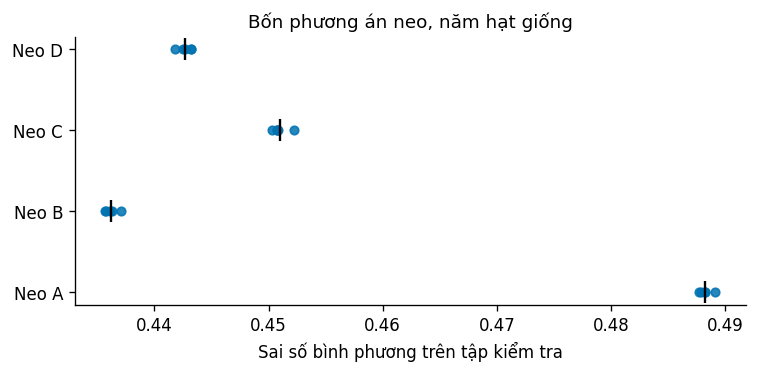

In [13]:
fig, ax = plt.subplots(figsize=(6.2, 3.0))
for i, neo in enumerate(NEO):
    v = np.array(gop[neo]["cac_gia_tri_mse"])
    ax.scatter(v, np.full_like(v, i, dtype=float), s=26, color=PALETTE[0],
               alpha=0.85, zorder=3)
    ax.scatter([v.mean()], [i], marker="|", s=170, color="black", zorder=4)
ax.set_yticks(range(len(NEO)))
ax.set_yticklabels(["Neo " + n for n in NEO])
ax.set_xlabel("Sai số bình phương trên tập kiểm tra")
ax.set_title("Bốn phương án neo, năm hạt giống")
luu_hinh(fig, "fig28_neo_nam_hat_giong.png")


In [14]:
bao_cao = {"kiem_tra_luc": datetime.datetime.now().isoformat(timespec="seconds"),
           "read_tag": READ_TAG, "run_tag": RUN_TAG, "nguon_ba_hat_giong": NGUON_ABCD,
           "hat_giong_moi": HAT_GIONG_MOI, "giao_thuc": meta["protocol"],
           "tong_hop_nam_hat_giong": gop, "thu_tu_tot_den_kem": thu_tu,
           "so_sanh_ba_va_nam_hat_giong": so_sanh_bang,
           "bat_cap_theo_benh_nhan": bat_cap, "env": ENV}
(RUN_DIR / "W2_neo_abcd_nam_hat_giong.json").write_text(
    json.dumps(bao_cao, ensure_ascii=False, indent=2))
print("Đã ghi", RUN_DIR / "W2_neo_abcd_nam_hat_giong.json")


Đã ghi /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/bo_sung_13_neo_abcd_nam_hat_giong/W2_neo_abcd_nam_hat_giong.json


## 7. Cách đọc kết quả

- `thu_tu_giu_nguyen` là dòng cần xem trước. Nếu thứ tự bốn neo đổi khi thêm hai hạt giống thì bảng ba hạt giống đã không đủ tin cậy, và mọi bảng khác trong đợt hai cũng cần được xem lại.
- Hai cột độ lệch chuẩn cho biết ước lượng cũ có bị đánh giá thấp hay không. Độ lệch chuẩn tính từ ba điểm rất không ổn định, nên việc nó thay đổi là bình thường, vấn đề chỉ là độ lớn của thay đổi.
- Con số cuối cùng đưa vào báo cáo tuần là bảng năm hạt giống ở đây, không phải bảng ba hạt giống ở notebook 04. Bảng cũ vẫn giữ lại trong phần phụ lục để người đọc theo dấu được toàn bộ quá trình.